# Homework 9: Latent Diffusion and Stable Diffusion

SID4: 2046

Latent Diffusion Model on FashionMNIST using a pretrained VAE, latent space diffusion, conditional U Net denoising, classifier free guidance, and conditional sampling.

In [3]:
import os
import random
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 2046

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Seed:", SEED)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Seed: 2046
Device: cuda
GPU: Tesla T4


In [4]:
!pip -q install diffusers transformers accelerate safetensors

## 1. VAE Compression and Latent Representation

FashionMNIST images are resized and converted to three channels for compatibility with the pretrained Stable Diffusion VAE. Images are encoded into the VAE latent space using the standard latent scaling factor of 0.18215. Reconstruction quality is evaluated using mean squared error.

In [5]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMAGE_SIZE = 128
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

train_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

images, labels = next(iter(test_loader))

print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Batch shape:", images.shape)
print("Label shape:", labels.shape)

100%|██████████| 26.4M/26.4M [00:00<00:00, 114MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.80MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 61.1MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.0MB/s]


Train images: 60000
Test images: 10000
Batch shape: torch.Size([64, 3, 128, 128])
Label shape: torch.Size([64])


In [6]:
from diffusers import AutoencoderKL

VAE_MODEL = "stabilityai/sd-vae-ft-mse"
LATENT_SCALE = 0.18215

vae = AutoencoderKL.from_pretrained(
    VAE_MODEL,
    torch_dtype=torch.float32,
).to(device)

vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad = False

print("VAE:", VAE_MODEL)
print("Latent scaling factor:", LATENT_SCALE)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE: stabilityai/sd-vae-ft-mse
Latent scaling factor: 0.18215


In [7]:
images = images.to(device)

with torch.no_grad():
    posterior = vae.encode(images).latent_dist

    latents_unscaled = posterior.mean
    latents = latents_unscaled * LATENT_SCALE

print("Input shape:", tuple(images.shape))
print("Latent shape:", tuple(latents.shape))
print("Latent dtype:", latents.dtype)
print("Latent min:", latents.min().item())
print("Latent max:", latents.max().item())
print("Latent mean:", latents.mean().item())
print("Latent std:", latents.std().item())

Input shape: (64, 3, 128, 128)
Latent shape: (64, 4, 16, 16)
Latent dtype: torch.float32
Latent min: -3.454496145248413
Latent max: 4.495213031768799
Latent mean: -0.04999128356575966
Latent std: 1.2648751735687256


In [8]:
with torch.no_grad():
    reconstructed = vae.decode(
        latents / LATENT_SCALE
    ).sample

reconstruction_mse = torch.mean(
    (reconstructed - images) ** 2
).item()

print("Reconstructed shape:", tuple(reconstructed.shape))
print("Reconstruction MSE:", reconstruction_mse)

Reconstructed shape: (64, 3, 128, 128)
Reconstruction MSE: 0.0007419202011078596


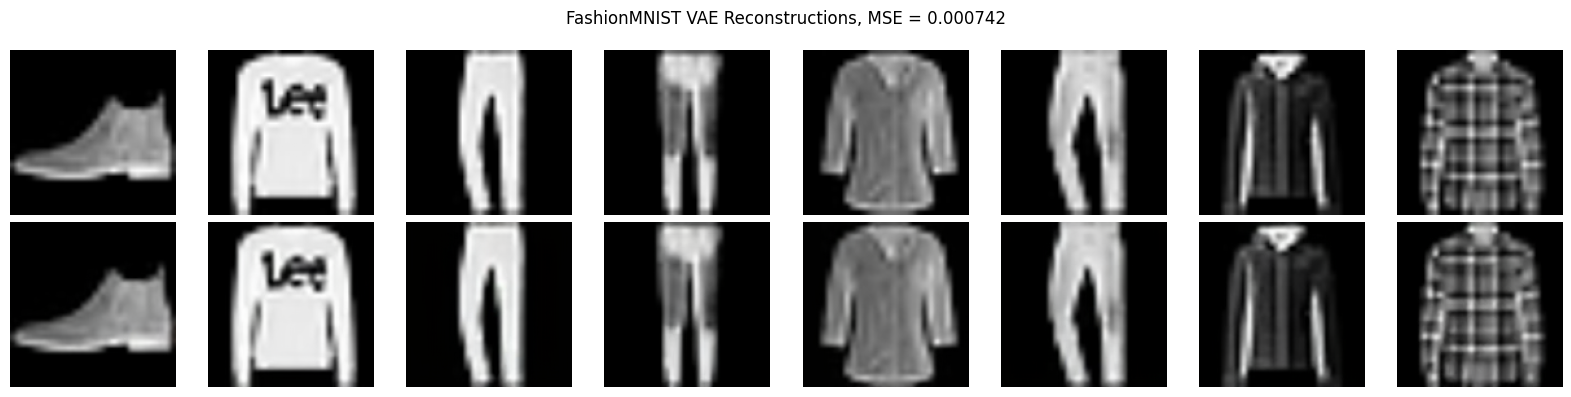

In [9]:
def to_display(x):
    return (
        x.detach()
        .cpu()
        .clamp(-1, 1)
        .add(1)
        .div(2)
    )

original_display = to_display(images)
reconstructed_display = to_display(reconstructed)

n_show = 8

fig, axes = plt.subplots(
    2,
    n_show,
    figsize=(16, 4)
)

for i in range(n_show):
    axes[0, i].imshow(
        original_display[i].permute(1, 2, 0)
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_display[i].permute(1, 2, 0)
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Reconstruction",
    fontsize=12
)

plt.suptitle(
    f"FashionMNIST VAE Reconstructions, MSE = {reconstruction_mse:.6f}"
)

plt.tight_layout()

plt.savefig(
    "/content/vae_reconstructions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [10]:
vae_metrics = {
    "vae_model": VAE_MODEL,
    "latent_scaling_factor": LATENT_SCALE,
    "input_shape": list(images.shape),
    "latent_shape": list(latents.shape),
    "reconstruction_mse": reconstruction_mse,
    "latent_mean": latents.mean().item(),
    "latent_std": latents.std().item(),
}

with open(
    "/content/vae_metrics.json",
    "w"
) as f:
    json.dump(
        vae_metrics,
        f,
        indent=2
    )

print(json.dumps(vae_metrics, indent=2))

{
  "vae_model": "stabilityai/sd-vae-ft-mse",
  "latent_scaling_factor": 0.18215,
  "input_shape": [
    64,
    3,
    128,
    128
  ],
  "latent_shape": [
    64,
    4,
    16,
    16
  ],
  "reconstruction_mse": 0.0007419202011078596,
  "latent_mean": -0.04999128356575966,
  "latent_std": 1.2648751735687256
}


## 2. Forward Diffusion in Latent Space

A Gaussian forward diffusion process is applied directly to the scaled VAE latent representation using 1000 diffusion timesteps and a linear beta schedule from 0.0001 to 0.02. Noisy latent states are decoded through the pretrained VAE to visualize progressive information destruction.

In [11]:
T = 1000
BETA_START = 1e-4
BETA_END = 0.02

betas = torch.linspace(
    BETA_START,
    BETA_END,
    T,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Diffusion timesteps:", T)
print("Beta start:", betas[0].item())
print("Beta end:", betas[-1].item())
print("Final alpha_bar:", alpha_bars[-1].item())

Diffusion timesteps: 1000
Beta start: 9.999999747378752e-05
Beta end: 0.019999999552965164
Final alpha_bar: 4.035829260828905e-05


In [12]:
def add_noise(x0, timestep, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    if timestep == 0:
        return x0, noise

    index = timestep - 1

    alpha_bar_t = alpha_bars[index]

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    return xt, noise


test_noise = torch.randn_like(latents[:1])

for t in [0, 200, 500, 800, 1000]:
    noisy_latent, _ = add_noise(
        latents[:1],
        t,
        test_noise
    )

    print(
        "t =",
        t,
        "mean =",
        round(noisy_latent.mean().item(), 4),
        "std =",
        round(noisy_latent.std().item(), 4)
    )

t = 0 mean = -0.1342 std = 1.3835
t = 200 mean = -0.088 std = 1.2807
t = 500 mean = -0.0031 std = 1.0764
t = 800 mean = 0.0307 std = 1.0448
t = 1000 mean = 0.0351 std = 1.044


In [13]:
TIMESTEPS_TO_SHOW = [0, 200, 500, 800, 1000]

example_latent = latents[:1]

torch.manual_seed(SEED)
fixed_noise = torch.randn_like(example_latent)

decoded_noisy_images = []

with torch.no_grad():
    for t in TIMESTEPS_TO_SHOW:
        noisy_latent, _ = add_noise(
            example_latent,
            t,
            fixed_noise
        )

        decoded = vae.decode(
            noisy_latent / LATENT_SCALE
        ).sample

        decoded_noisy_images.append(
            to_display(decoded[0])
        )

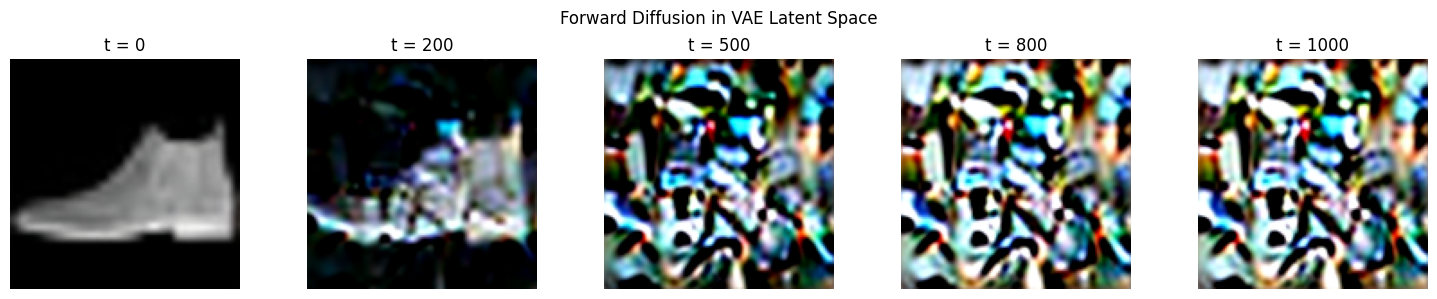

In [14]:
fig, axes = plt.subplots(
    1,
    len(TIMESTEPS_TO_SHOW),
    figsize=(15, 3)
)

for ax, image, t in zip(
    axes,
    decoded_noisy_images,
    TIMESTEPS_TO_SHOW
):
    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(f"t = {t}")
    ax.axis("off")

plt.suptitle(
    "Forward Diffusion in VAE Latent Space"
)

plt.tight_layout()

plt.savefig(
    "/content/latent_forward_diffusion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 3. Conditional Denoising Architecture

The denoiser operates directly on 4 channel VAE latents. It uses base channels of 64 with channel multipliers 1, 2, and 4, sinusoidal timestep embeddings, residual blocks with GroupNorm and SiLU, self attention, skip connections, and class conditioning.

FashionMNIST labels 0 through 9 are represented by learned embeddings. An additional null label is reserved for classifier free guidance.

In [15]:
import torch.nn as nn
import torch.nn.functional as F


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2

        frequencies = torch.exp(
            torch.arange(
                half,
                device=t.device,
                dtype=torch.float32
            )
            * (
                -math.log(10000)
                / max(half - 1, 1)
            )
        )

        angles = t.float()[:, None] * frequencies[None, :]

        embedding = torch.cat(
            [
                torch.sin(angles),
                torch.cos(angles)
            ],
            dim=1
        )

        return embedding

In [16]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, emb_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            8,
            in_channels
        )

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.emb_projection = nn.Linear(
            emb_dim,
            out_channels
        )

        self.norm2 = nn.GroupNorm(
            8,
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        if in_channels == out_channels:
            self.skip = nn.Identity()
        else:
            self.skip = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )

    def forward(self, x, emb):
        h = self.conv1(
            F.silu(
                self.norm1(x)
            )
        )

        emb_out = self.emb_projection(
            F.silu(emb)
        )

        h = h + emb_out[:, :, None, None]

        h = self.conv2(
            F.silu(
                self.norm2(h)
            )
        )

        return h + self.skip(x)

In [17]:
class SelfAttention2d(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()

        self.norm = nn.GroupNorm(
            8,
            channels
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):
        batch, channels, height, width = x.shape

        h = self.norm(x)

        h = h.flatten(2).transpose(1, 2)

        h, _ = self.attention(
            h,
            h,
            h,
            need_weights=False
        )

        h = h.transpose(1, 2).reshape(
            batch,
            channels,
            height,
            width
        )

        return x + h

In [18]:
class ConditionalLatentUNet(nn.Module):
    def __init__(
        self,
        latent_channels=4,
        base_channels=64,
        num_classes=10
    ):
        super().__init__()

        self.num_classes = num_classes
        self.null_label = num_classes

        time_dim = base_channels * 4

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(base_channels),
            nn.Linear(
                base_channels,
                time_dim
            ),
            nn.SiLU(),
            nn.Linear(
                time_dim,
                time_dim
            )
        )

        self.label_embedding = nn.Embedding(
            num_classes + 1,
            time_dim
        )

        self.input_conv = nn.Conv2d(
            latent_channels,
            base_channels,
            kernel_size=3,
            padding=1
        )

        self.down1 = ResidualBlock(
            base_channels,
            base_channels,
            time_dim
        )

        self.attn16 = SelfAttention2d(
            base_channels
        )

        self.downsample1 = nn.Conv2d(
            base_channels,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down2 = ResidualBlock(
            base_channels * 2,
            base_channels * 2,
            time_dim
        )

        self.downsample2 = nn.Conv2d(
            base_channels * 2,
            base_channels * 4,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down3 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid1 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid_attention = SelfAttention2d(
            base_channels * 4
        )

        self.mid2 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            base_channels * 4,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up2 = ResidualBlock(
            base_channels * 4,
            base_channels * 2,
            time_dim
        )

        self.upsample1 = nn.ConvTranspose2d(
            base_channels * 2,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up1 = ResidualBlock(
            base_channels * 2,
            base_channels,
            time_dim
        )

        self.output_norm = nn.GroupNorm(
            8,
            base_channels
        )

        self.output_conv = nn.Conv2d(
            base_channels,
            latent_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, timesteps, labels):
        time_emb = self.time_embedding(
            timesteps
        )

        label_emb = self.label_embedding(
            labels
        )

        emb = time_emb + label_emb

        x0 = self.input_conv(x)

        d1 = self.down1(
            x0,
            emb
        )

        d1 = self.attn16(d1)

        d2 = self.downsample1(d1)

        d2 = self.down2(
            d2,
            emb
        )

        d3 = self.downsample2(d2)

        d3 = self.down3(
            d3,
            emb
        )

        h = self.mid1(
            d3,
            emb
        )

        h = self.mid_attention(h)

        h = self.mid2(
            h,
            emb
        )

        h = self.upsample2(h)

        h = torch.cat(
            [h, d2],
            dim=1
        )

        h = self.up2(
            h,
            emb
        )

        h = self.upsample1(h)

        h = torch.cat(
            [h, d1],
            dim=1
        )

        h = self.up1(
            h,
            emb
        )

        h = self.output_conv(
            F.silu(
                self.output_norm(h)
            )
        )

        return h

In [19]:
denoiser = ConditionalLatentUNet().to(device)

test_latents = torch.randn(
    4,
    4,
    16,
    16,
    device=device
)

test_timesteps = torch.tensor(
    [0, 200, 500, 999],
    device=device
)

test_labels = torch.tensor(
    [0, 3, 7, 10],
    device=device
)

with torch.no_grad():
    test_output = denoiser(
        test_latents,
        test_timesteps,
        test_labels
    )

parameter_count = sum(
    p.numel()
    for p in denoiser.parameters()
)

print("Input shape:", tuple(test_latents.shape))
print("Output shape:", tuple(test_output.shape))
print("Parameter count:", parameter_count)
print("Null label index:", denoiser.null_label)

assert test_output.shape == test_latents.shape
assert denoiser.null_label == 10

print("Architecture test passed.")

Input shape: (4, 4, 16, 16)
Output shape: (4, 4, 16, 16)
Parameter count: 6486852
Null label index: 10
Architecture test passed.


In [20]:
LABEL_DROP_PROB = 0.1
NULL_LABEL = 10

def apply_classifier_free_dropout(
    labels,
    drop_probability=LABEL_DROP_PROB
):
    labels = labels.clone()

    drop_mask = torch.rand(
        labels.shape,
        device=labels.device
    ) < drop_probability

    labels[drop_mask] = NULL_LABEL

    return labels, drop_mask

In [21]:
test_labels = torch.arange(
    10,
    device=device
).repeat(1000)

dropped_labels, drop_mask = apply_classifier_free_dropout(
    test_labels
)

observed_drop_rate = drop_mask.float().mean().item()

print("Configured drop probability:", LABEL_DROP_PROB)
print("Observed drop rate:", observed_drop_rate)
print(
    "Null labels:",
    (dropped_labels == NULL_LABEL).sum().item()
)
print(
    "Total labels:",
    dropped_labels.numel()
)

assert set(
    dropped_labels.unique().cpu().tolist()
).issubset(set(range(11)))

print("Classifier free label dropout test passed.")

Configured drop probability: 0.1
Observed drop rate: 0.09939999878406525
Null labels: 994
Total labels: 10000
Classifier free label dropout test passed.


## 4. Training

The pretrained VAE remains frozen. FashionMNIST images are encoded once into scaled latent representations and cached. The conditional U Net is then trained for 50 epochs with a learning rate of 2e 5 to predict Gaussian noise added at randomly sampled diffusion timesteps. During training, class labels are replaced by the null label with probability 0.1 for classifier free guidance.

In [22]:
from tqdm.auto import tqdm
from torch.utils.data import TensorDataset, DataLoader

CACHE_BATCH_SIZE = 128

cache_loader = DataLoader(
    train_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

cached_latents = []
cached_labels = []

vae.eval()

with torch.no_grad():
    for batch_images, batch_labels in tqdm(
        cache_loader,
        desc="Encoding FashionMNIST"
    ):
        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        batch_latents = (
            vae.encode(batch_images)
            .latent_dist.mean
            * LATENT_SCALE
        )

        cached_latents.append(
            batch_latents.cpu()
        )

        cached_labels.append(
            batch_labels.cpu()
        )

train_latents = torch.cat(
    cached_latents,
    dim=0
)

train_labels = torch.cat(
    cached_labels,
    dim=0
)

print("Cached latents:", train_latents.shape)
print("Cached labels:", train_labels.shape)
print("Latent mean:", train_latents.mean().item())
print("Latent std:", train_latents.std().item())

assert train_latents.shape == (
    60000,
    4,
    16,
    16
)

assert train_labels.shape == (60000,)

print("Latent cache verified.")

Encoding FashionMNIST:   0%|          | 0/469 [00:00<?, ?it/s]

Cached latents: torch.Size([60000, 4, 16, 16])
Cached labels: torch.Size([60000])
Latent mean: -0.045213159173727036
Latent std: 1.260416030883789
Latent cache verified.


In [23]:
LATENT_BATCH_SIZE = 128

latent_dataset = TensorDataset(
    train_latents,
    train_labels
)

train_latent_loader = DataLoader(
    latent_dataset,
    batch_size=LATENT_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(latent_dataset))
print("Batches per epoch:", len(train_latent_loader))

batch_latents, batch_labels = next(
    iter(train_latent_loader)
)

print("Latent batch:", batch_latents.shape)
print("Label batch:", batch_labels.shape)

Training samples: 60000
Batches per epoch: 469
Latent batch: torch.Size([128, 4, 16, 16])
Label batch: torch.Size([128])


In [24]:
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

denoiser = ConditionalLatentUNet().to(device)

TRAIN_EPOCHS = 50
LEARNING_RATE = 2e-5

optimizer = torch.optim.AdamW(
    denoiser.parameters(),
    lr=LEARNING_RATE
)

print("Training epochs:", TRAIN_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in denoiser.parameters()
        if p.requires_grad
    )
)

Training epochs: 50
Learning rate: 2e-05
Trainable parameters: 6486852


In [25]:
denoiser.train()

benchmark_start = time.perf_counter()

for step, (clean_latents, labels) in enumerate(train_latent_loader):

    clean_latents = clean_latents.to(
        device,
        non_blocking=True
    )

    labels = labels.to(
        device,
        non_blocking=True
    )

    batch_size = clean_latents.size(0)

    timesteps = torch.randint(
        1,
        T + 1,
        (batch_size,),
        device=device
    )

    noise = torch.randn_like(clean_latents)

    alpha_bar_t = alpha_bars[
        timesteps - 1
    ].view(
        batch_size,
        1,
        1,
        1
    )

    noisy_latents = (
        torch.sqrt(alpha_bar_t) * clean_latents
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    conditioned_labels, _ = apply_classifier_free_dropout(
        labels
    )

    optimizer.zero_grad(set_to_none=True)

    predicted_noise = denoiser(
        noisy_latents,
        timesteps - 1,
        conditioned_labels
    )

    loss = F.mse_loss(
        predicted_noise,
        noise
    )

    loss.backward()

    optimizer.step()

    if step == 49:
        break

benchmark_seconds = time.perf_counter() - benchmark_start

estimated_epoch_seconds = (
    benchmark_seconds
    * len(train_latent_loader)
    / 50
)

estimated_total_minutes = (
    estimated_epoch_seconds
    * TRAIN_EPOCHS
    / 60
)

print("50 batch benchmark seconds:", benchmark_seconds)
print("Estimated seconds per epoch:", estimated_epoch_seconds)
print("Estimated 50 epoch training minutes:", estimated_total_minutes)

50 batch benchmark seconds: 3.8897866949998843
Estimated seconds per epoch: 36.48619919909891
Estimated 50 epoch training minutes: 30.405165999249096


In [29]:
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

denoiser = ConditionalLatentUNet().to(device)

TRAIN_EPOCHS = 50
LEARNING_RATE = 2e-5

optimizer = torch.optim.AdamW(
    denoiser.parameters(),
    lr=LEARNING_RATE
)

print("Fresh model initialized.")
print("Epochs:", TRAIN_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Fresh model initialized.
Epochs: 50
Learning rate: 2e-05


In [30]:
training_history = []

best_loss = float("inf")
best_epoch = None
best_state = None

training_start = time.perf_counter()

for epoch in range(1, TRAIN_EPOCHS + 1):

    denoiser.train()

    running_loss = 0.0
    sample_count = 0

    epoch_start = time.perf_counter()

    progress = tqdm(
        train_latent_loader,
        desc=f"Epoch {epoch:02d}/{TRAIN_EPOCHS}",
        leave=False
    )

    for clean_latents, labels in progress:

        clean_latents = clean_latents.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        batch_size = clean_latents.size(0)

        timesteps = torch.randint(
            1,
            T + 1,
            (batch_size,),
            device=device
        )

        noise = torch.randn_like(clean_latents)

        alpha_bar_t = alpha_bars[
            timesteps - 1
        ].view(
            batch_size,
            1,
            1,
            1
        )

        noisy_latents = (
            torch.sqrt(alpha_bar_t) * clean_latents
            + torch.sqrt(1.0 - alpha_bar_t) * noise
        )

        conditioned_labels, _ = (
            apply_classifier_free_dropout(labels)
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        predicted_noise = denoiser(
            noisy_latents,
            timesteps - 1,
            conditioned_labels
        )

        loss = F.mse_loss(
            predicted_noise,
            noise
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            denoiser.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * batch_size
        sample_count += batch_size

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / sample_count
    epoch_seconds = time.perf_counter() - epoch_start

    training_history.append({
        "epoch": epoch,
        "loss": epoch_loss,
        "seconds": epoch_seconds
    })

    if epoch_loss < best_loss:
        best_loss = epoch_loss
        best_epoch = epoch

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in denoiser.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}/{TRAIN_EPOCHS}  "
        f"loss={epoch_loss:.6f}  "
        f"time={epoch_seconds:.1f}s"
    )

training_seconds = time.perf_counter() - training_start

print()
print("Training complete.")
print("Best epoch:", best_epoch)
print("Best loss:", best_loss)
print("Total training seconds:", training_seconds)

Epoch 01/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 01/50  loss=0.408183  time=34.6s


Epoch 02/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 02/50  loss=0.190618  time=34.7s


Epoch 03/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 03/50  loss=0.156800  time=34.4s


... (125 outputs left out)

Epoch 49/50  loss=0.100216  time=34.9s


Epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f8c4126da80>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f8c4126da80>Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    AssertionErrorif w.is_alive():
:   File "/usr/lib/python3.13/multiprocessing/pro

Epoch 50/50  loss=0.099971  time=35.0s

Training complete.
Best epoch: 50
Best loss: 0.09997120491266251
Total training seconds: 1738.1947121809999


In [31]:
import pandas as pd

denoiser.load_state_dict(best_state)
denoiser.eval()

torch.save(
    {
        "model_state_dict": best_state,
        "best_epoch": best_epoch,
        "best_loss": best_loss,
        "training_seconds": training_seconds,
        "seed": SEED,
        "epochs": TRAIN_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "latent_scale": LATENT_SCALE,
    },
    "/content/hw9_best_denoiser.pt"
)

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    "/content/training_history.csv",
    index=False
)

print("Best checkpoint restored and saved.")
print("Best epoch:", best_epoch)
print("Best loss:", best_loss)

Best checkpoint restored and saved.
Best epoch: 50
Best loss: 0.09997120491266251


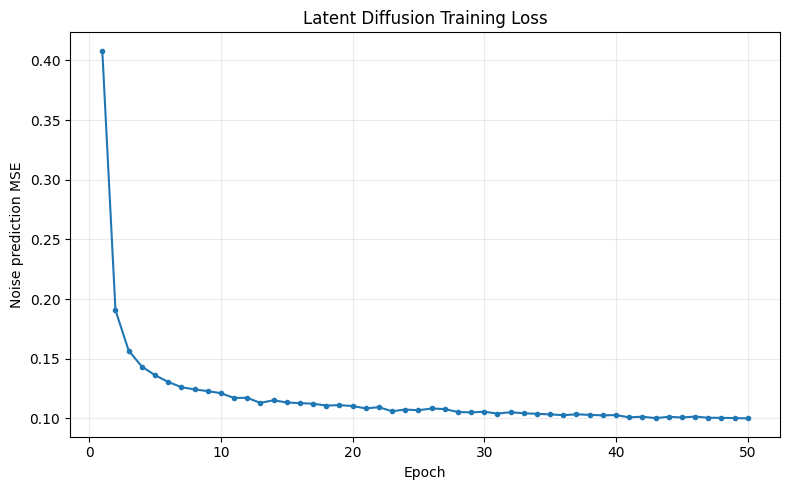

Initial loss: 0.40818275731404624
Final loss: 0.09997120491266251
Loss reduction: 0.30821155240138376


In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["loss"],
    marker="o",
    markersize=3
)

plt.xlabel("Epoch")
plt.ylabel("Noise prediction MSE")
plt.title("Latent Diffusion Training Loss")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "/content/training_loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Initial loss:",
    history_df.iloc[0]["loss"]
)

print(
    "Final loss:",
    history_df.iloc[-1]["loss"]
)

print(
    "Loss reduction:",
    history_df.iloc[0]["loss"]
    - history_df.iloc[-1]["loss"]
)

## 5. Classifier Free Guidance Sampling

Sampling begins from Gaussian noise in the VAE latent space. At each reverse diffusion timestep, the denoiser produces both conditional and unconditional noise predictions. These predictions are combined using classifier free guidance with a guidance scale of 7.5. The final denoised latents are decoded through the pretrained VAE.

In [33]:
GUIDANCE_SCALE = 7.5
NUM_SAMPLES = 64

sample_labels = torch.tensor(
    [i % 10 for i in range(NUM_SAMPLES)],
    device=device,
    dtype=torch.long
)

print("Samples:", NUM_SAMPLES)
print("Guidance scale:", GUIDANCE_SCALE)
print("Labels:", sample_labels.cpu().tolist())

Samples: 64
Guidance scale: 7.5
Labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3]


In [34]:
@torch.no_grad()
def guided_noise_prediction(
    model,
    x,
    timestep,
    labels,
    guidance_scale=GUIDANCE_SCALE
):
    batch_size = x.size(0)

    t = torch.full(
        (batch_size,),
        timestep,
        device=x.device,
        dtype=torch.long
    )

    null_labels = torch.full(
        (batch_size,),
        NULL_LABEL,
        device=x.device,
        dtype=torch.long
    )

    eps_cond = model(
        x,
        t,
        labels
    )

    eps_uncond = model(
        x,
        t,
        null_labels
    )

    eps_guided = (
        eps_uncond
        + guidance_scale
        * (eps_cond - eps_uncond)
    )

    return eps_guided

In [35]:
@torch.no_grad()
def sample_latents(
    model,
    labels,
    guidance_scale=GUIDANCE_SCALE
):
    model.eval()

    batch_size = labels.size(0)

    x = torch.randn(
        batch_size,
        4,
        16,
        16,
        device=device
    )

    for t in tqdm(
        reversed(range(T)),
        total=T,
        desc="Sampling"
    ):
        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]

        predicted_noise = guided_noise_prediction(
            model,
            x,
            t,
            labels,
            guidance_scale
        )

        mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            )
            * predicted_noise
        )

        if t > 0:
            noise = torch.randn_like(x)

            x = (
                mean
                + torch.sqrt(beta_t) * noise
            )
        else:
            x = mean

    return x

In [36]:
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

generated_latents = sample_latents(
    denoiser,
    sample_labels,
    guidance_scale=GUIDANCE_SCALE
)

with torch.no_grad():
    generated_images = vae.decode(
        generated_latents / LATENT_SCALE
    ).sample

generated_images = to_display(
    generated_images
)

print(
    "Generated latent shape:",
    tuple(generated_latents.shape)
)

print(
    "Generated image shape:",
    tuple(generated_images.shape)
)

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated latent shape: (64, 4, 16, 16)
Generated image shape: (64, 3, 128, 128)


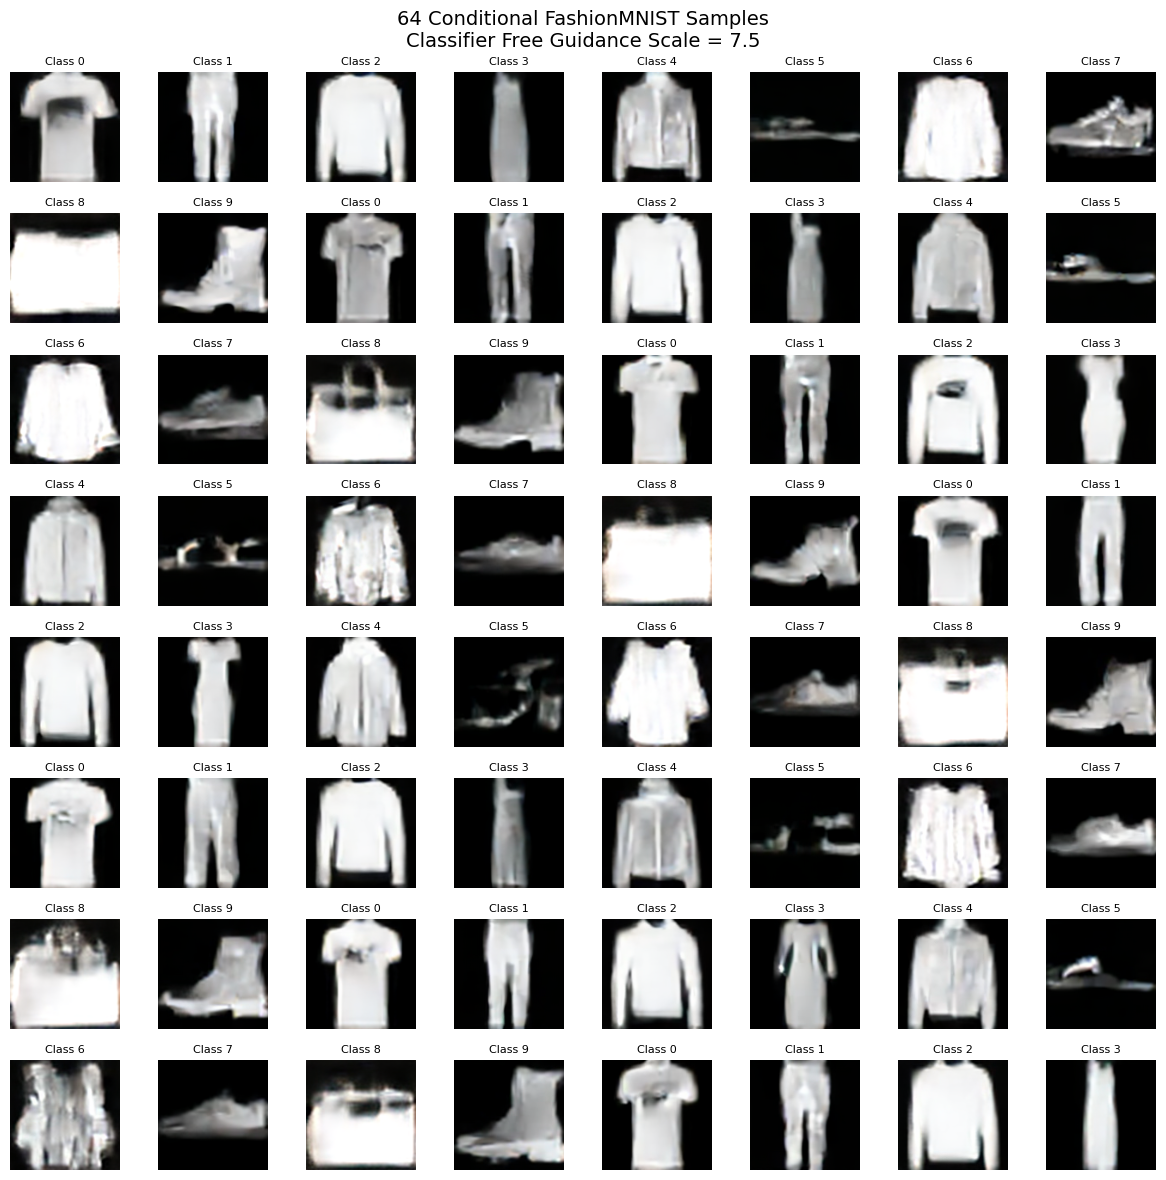

In [37]:
fig, axes = plt.subplots(
    8,
    8,
    figsize=(12, 12)
)

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i]
        .permute(1, 2, 0)
        .cpu()
    )

    ax.set_title(
        f"Class {sample_labels[i].item()}",
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    "64 Conditional FashionMNIST Samples\n"
    f"Classifier Free Guidance Scale = {GUIDANCE_SCALE}",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "/content/conditional_samples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()